# Experiment 3: NLP Pre-processing Tasks
**Mini-project:** Resume Analyzer Using Natural Language Processing (Group 28)

**Objective:** Implement HTML/special-character removal, whitespace cleaning, sentence segmentation, contraction expansion, lowercasing, number handling, stop-word removal, phrase extraction, tokenization and script validation on resume text.

Open in Colab: [Exp3_Preprocessing.ipynb](https://colab.research.google.com/github/GnsShubham06/resume-analyzer-nlp/blob/main/notebooks/experiments/Exp3_Preprocessing.ipynb) &nbsp;|&nbsp; Run with **Runtime → Run all**.
Data: 100 resumes (20 per domain); the screenshots in the report use five fictional (synthetic) resumes.

In [1]:
# ---- Setup: runs in Google Colab and locally --------------------------------
# In Colab this cell downloads the project repository (code + anonymised
# dataset) from GitHub and installs the packages Colab does not ship with.
import os, sys, subprocess, warnings
warnings.filterwarnings("ignore")
REPO = "https://github.com/GnsShubham06/resume-analyzer-nlp"
if "google.colab" in sys.modules:
    if not os.path.isdir("/content/resume-analyzer-nlp"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/resume-analyzer-nlp"], check=True)
    os.chdir("/content/resume-analyzer-nlp")
    extra = ['contractions', 'langdetect']
    if extra:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *extra], check=True)
else:  # local run from notebooks/experiments/
    for _ in range(3):
        if os.path.isfile("requirements.txt"):
            break
        os.chdir("..")
sys.path.insert(0, os.getcwd())

import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)

import spacy
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:  # model not installed yet (fresh Colab runtime)
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm", "-q"], check=True)
    import importlib, site
    importlib.invalidate_caches(); importlib.reload(site)
    import en_core_web_sm
    nlp = en_core_web_sm.load()

%config InlineBackend.figure_format = "retina"
import pandas as pd
pd.set_option("display.max_colwidth", 120)
df = pd.read_csv("data/resume_dataset.csv")
df["extracted_text"] = df["extracted_text"].fillna("")
print("Project folder:", os.path.basename(os.getcwd()), "| resumes:", len(df))

Project folder: resume-analyzer-nlp | resumes: 100


In [2]:
# Five fictional (synthetic) resumes used for the screenshots - one per domain
SAMPLE_IDS = {"Engineering": "ENG_06", "HR": "HR_06", "Finance": "FIN_07",
              "Healthcare": "HLT_04", "Agriculture": "AGR_02"}
FOOTER = "Synthetic resume - fictional person"
def resume_text(rid):
    """Raw text of a fictional resume, without the 'synthetic resume' footer line."""
    t = df.set_index("resume_id").loc[rid, "extracted_text"]
    return "\n".join(l for l in t.split("\n") if not l.startswith(FOOTER)).strip()

import html, re
raw = resume_text("FIN_07")          # fictional Finance resume (Daniel Gill)
SECTION = {"Summary", "Key Skills", "Professional Experience", "Education and Training",
           "Training & Certifications", "Languages"}
def to_html(text):
    """Wrap the resume in HTML the way job portals export resumes."""
    lines = text.split("\n")
    out = ["<html> <body> ", f"<h1>{lines[0]}</h1>", f"<h2>{lines[1]}</h2>"]
    for l in lines[2:]:
        if l.startswith("- "):
            out.append(f"<li>{html.escape(l[2:])}</li>")
        elif l in SECTION:
            out.append(f"<h3>{html.escape(l)}</h3>")
        else:
            out.append(f"<p>{html.escape(l)}</p>")
    return "".join(out + ["</body></html>"])
raw_html = to_html(raw)
print(raw_html[:400])

<html> <body> <h1>Daniel Gill</h1><h2>Finance Manager</h2><p>Hyderabad | daniel.gill@example.com | +1 555-0111</p><h3>Summary</h3><p>Finance professional with 2 years in financial planning and analysis, experienced in month-end close,</p><p>variance analysis and audit support.</p><h3>Key Skills</h3><p>Stakeholder management · Cost accounting · Month-end close · Accounts payable · Accounts receivab


## a. HTML / special characters and whitespace

In [3]:
BLOCK = r"</?(?:p|div|h[1-6]|li|ul|ol|br|tr|table|body|html)[^>]*>"
def remove_html(t):
    t = re.sub(BLOCK, "\n", t)                    # block tags -> new line
    t = re.sub(r"<[^>]+>", "", t)                 # other tags
    t = html.unescape(t).replace("\xa0", " ")     # &amp; &nbsp; ...
    t = re.sub(r"\s*[|]\s*", "   ", t)            # separators
    t = re.sub(r"[ \t]*[·•▪●][ \t]*", " , ", t)  # bullets inside skill lists
    t = re.sub(r"[^\w\s.,;:'()%&+#/@-]", " ", t)  # keep meaningful symbols: % & + # (C++, C#, 14%)
    return t
def clean_whitespace(t):
    t = re.sub(r"[ \t]+", " ", t)
    return "\n".join(l.strip() for l in t.split("\n") if l.strip())
no_html = remove_html(raw_html)
clean = clean_whitespace(no_html)
print(repr(no_html[:170])); print("---"); print("\n".join(clean.split("\n")[:10]))

'\n \n \nDaniel Gill\n\nFinance Manager\n\nHyderabad   daniel.gill@example.com   +1 555-0111\n\nSummary\n\nFinance professional with 2 years in financial planning and analysis, exper'
---
Daniel Gill
Finance Manager
Hyderabad daniel.gill@example.com +1 555-0111
Summary
Finance professional with 2 years in financial planning and analysis, experienced in month-end close,
variance analysis and audit support.
Key Skills
Stakeholder management , Cost accounting , Month-end close , Accounts payable , Accounts receivable ,
Ind AS , MS Office , Financial modelling , Tally ERP , Team leadership , Reconciliation , Credit analysis ,
Internal audit , GST , Valuation , Variance analysis


## b. Sentence segmentation and contractions

In [4]:
naive = [s for s in clean.replace("\n", " ").split(".") if s.strip()]
nltk_sents = nltk.sent_tokenize(clean)
resume_aware = [s for line in clean.split("\n") for s in nltk.sent_tokenize(line)]
print(f"naive split on '.': {len(naive)} | NLTK sent_tokenize: {len(nltk_sents)} | "
      f"resume-aware (lines + NLTK): {len(resume_aware)}")
for s in resume_aware[5:10]:
    print("  *", s)

naive split on '.': 13 | NLTK sent_tokenize: 11 | resume-aware (lines + NLTK): 31
  * variance analysis and audit support.
  * Key Skills
  * Stakeholder management , Cost accounting , Month-end close , Accounts payable , Accounts receivable ,
  * Ind AS , MS Office , Financial modelling , Tally ERP , Team leadership , Reconciliation , Credit analysis ,
  * Internal audit , GST , Valuation , Variance analysis


In [5]:
import contractions
demo = "I'm a finance professional and I've led audits; I'd like a role where I can't stop learning."
print(contractions.fix(demo, slang=False))
names = "Bachelor's degree from Children's College, D'Souza & Co."
print(contractions.fix(names, slang=False), " <- possessives/names kept")
lower = clean.replace("\n", " | ").lower()
print("lowercased:", lower[:130])

I am a finance professional and I have led audits; I would like a role where I cannot stop learning.
Bachelor's degree from Children's College, D'Souza & Co.  <- possessives/names kept
lowercased: daniel gill | finance manager | hyderabad daniel.gill@example.com +1 555-0111 | summary | finance professional with 2 years in fin


## c. Number handling

In [6]:
num_demo = ("Built a three-statement model to evaluate a USD 275K expansion; closed 32 outlets in 2024; "
            "cut costs by 14%.").lower()
def tag_numbers(t):
    t = re.sub(r"(?:usd|inr|rs\.?)\s?\d[\d,.]*\s?[kmb]?\b", " <MONEY> ", t)
    t = re.sub(r"\d+(?:\.\d+)?\s?%", " <PERCENT> ", t)
    t = re.sub(r"\b(?:19|20)\d{2}\b", " <YEAR> ", t)
    t = re.sub(r"\b\d+(?:[.,]\d+)*\b", " <NUM> ", t)
    return re.sub(r"\s+", " ", t).strip()
def remove_numbers(t, keep_years=True):
    year = r"(?!(?:19|20)\d{2}\b)" if keep_years else ""
    t = re.sub(r"\b" + year + r"\d[\d,.]*[kmb]?%?", "", t)
    return re.sub(r"\s+", " ", t).strip()
print("tag   :", tag_numbers(num_demo))
print("remove:", remove_numbers(num_demo))

tag   : built a three-statement model to evaluate a <MONEY> expansion; closed <NUM> outlets in <YEAR> ; cut costs by <PERCENT> .
remove: built a three-statement model to evaluate a usd expansion; closed outlets in 2024; cut costs by .


## d. Tokenization, stop-word removal and phrase extraction

In [7]:
from nltk.corpus import stopwords
from spacy.matcher import PhraseMatcher
counts = {"whitespace": len(clean.split()), "regex \\w+": len(re.findall(r"\w+", clean)),
          "NLTK": len(nltk.word_tokenize(clean)), "spaCy": len(nlp(clean))}
print("token counts:", counts)
tokens = [t.strip(".-") for t in re.findall(r"\+?\w[\w.+#&%-]*", lower)]
tokens = [t for t in tokens if t]
STOP = set(stopwords.words("english"))
kept = [t for t in tokens if t not in STOP]
print(f"stop-word removal: {len(tokens)} -> {len(kept)} tokens;", kept[:15])

token counts: {'whitespace': 218, 'regex \\w+': 213, 'NLTK': 240, 'spaCy': 290}
stop-word removal: 201 -> 167 tokens; ['daniel', 'gill', 'finance', 'manager', 'hyderabad', 'daniel.gill', 'example.com', '+1', '555-0111', 'summary', 'finance', 'professional', '2', 'years', 'financial']


In [8]:
# our multi-word Finance skill list (single words are matched by the tokenizer anyway)
multi_word = ["accounts payable", "accounts receivable", "cost accounting", "credit analysis", "financial modelling",
              "internal audit", "month-end close", "ms office", "stakeholder management", "tally erp",
              "variance analysis", "financial reporting", "budgeting and forecasting", "cash flow", "general ledger",
              "risk management", "tax planning", "fund accounting", "profit and loss", "balance sheet"]
matcher = PhraseMatcher(nlp.vocab, attr="LOWER")
matcher.add("SKILL", [nlp.make_doc(s) for s in multi_word])
doc = nlp(clean)
skills = sorted({doc[s:e].text.lower() for _, s, e in matcher(doc)})
print("skill phrases :", skills)
bullets = [l[2:] for l in raw.split("\n") if l.startswith("- ")][1:6]
print("noun phrases  :", [c.text for b in bullets for c in nlp(b).noun_chunks][:12])

skill phrases : ['accounts payable', 'accounts receivable', 'cost accounting', 'credit analysis', 'financial modelling', 'internal audit', 'month-end close', 'ms office', 'stakeholder management', 'tally erp', 'variance analysis']


noun phrases  : ['Drafted board-pack financial summaries', 'KPI dashboards', 'Valued listed companies', 'DCF and comparable-multiples methods', 'research notes', 'Prepared working-capital analysis', 'that', 'about USD 239K', 'cash', 'a vendor-payment calendar', 'that', 'late-payment charges']


## e. Script validation

In [9]:
import unicodedata
from langdetect import DetectorFactory, detect_langs
DetectorFactory.seed = 0
def script_check(text):
    letters = [c for c in text if c.isalpha()]
    latin = sum("LATIN" in unicodedata.name(c, "") for c in letters) / max(len(letters), 1)
    lang = detect_langs(text)[0]
    return {"letters": len(letters), "latin_share": round(latin, 3), "language": f"{lang.lang}:{lang.prob}",
            "valid_english_latin": latin > 0.9 and lang.lang == "en"}
hindi = "मैं वित्त प्रबंधक हूँ और बजट बनाता हूँ"
print("Finance resume :", script_check(clean))
print("Hindi test line:", script_check(hindi))

Finance resume : {'letters': 1268, 'latin_share': 1.0, 'language': 'en:0.999995356420528', 'valid_english_latin': True}
Hindi test line: {'letters': 19, 'latin_share': 0.0, 'language': 'hi:0.9999972953192295', 'valid_english_latin': False}


## Visualising the effect of pre-processing

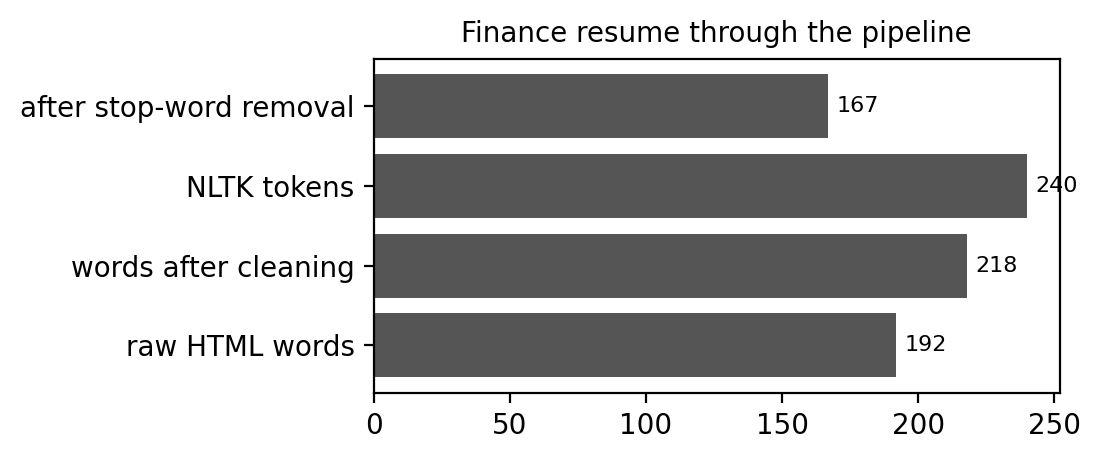

In [10]:
import matplotlib.pyplot as plt
steps = {"raw HTML words": len(raw_html.split()), "words after cleaning": len(clean.split()),
         "NLTK tokens": len(nltk.word_tokenize(clean)), "after stop-word removal": len(kept)}
fig, ax = plt.subplots(figsize=(5.6, 2.4))
bars = ax.barh(list(steps), list(steps.values()), color="#555555")
ax.bar_label(bars, padding=3, fontsize=8); ax.set_title("Finance resume through the pipeline", fontsize=10)
plt.tight_layout(); plt.show()